# U-Net + ResNet-50 — IAN Canal & M3M Segmentation
## Full Training Run — Dental X-Ray

> **AMD RX 6800 / Windows 11 version** — uses `torch-directml` instead of CUDA.
> All Colab-specific code (Drive mount, `/content/` paths) has been replaced with local paths.


## 1. Setup & Installation

Install dependencies for **AMD GPU on Windows 11** via DirectML.


In [1]:
# Install PyTorch (CPU build) + DirectML backend for AMD GPU on Windows
# Run these in your terminal/Anaconda prompt ONCE before launching Jupyter:
#
!pip install torch==2.2.0 torchvision==0.17.0 --index-url https://download.pytorch.org/whl/cpu
!pip install torch-directml
!pip install segmentation-models-pytorch albumentations opencv-python tqdm scipy pandas matplotlib

import torch
import torch_directml

print(f'PyTorch  : {torch.__version__}')
print(f'DirectML : torch_directml available')
dml_device = torch_directml.device()
print(f'DML device: {dml_device}')


Looking in indexes: https://download.pytorch.org/whl/cpu
  Using cached https://download.pytorch.org/whl/cpu/torch-2.2.0%2Bcpu-cp312-cp312-win_amd64.whl (200.7 MB)
  Using cached https://download.pytorch.org/whl/cpu/torchvision-0.17.0%2Bcpu-cp312-cp312-win_amd64.whl (1.2 MB)

  Attempting uninstall: torch

    Found existing installation: torch 2.4.1

   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
    Uninstalling torch-2.4.1:
   ---------------------------------------- 0/2 [torch]
      Successfully uninstalled torch-2.4.1
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ----------

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torch-directml 0.2.5.dev240914 requires torch==2.4.1, but you have torch 2.2.0+cpu which is incompatible.
torch-directml 0.2.5.dev240914 requires torchvision==0.19.1, but you have torchvision 0.17.0+cpu which is incompatible.


  Using cached torch-2.4.1-cp312-cp312-win_amd64.whl.metadata (27 kB)
  Using cached torchvision-0.19.1-cp312-cp312-win_amd64.whl.metadata (6.1 kB)
Using cached torch-2.4.1-cp312-cp312-win_amd64.whl (199.4 MB)
Using cached torchvision-0.19.1-cp312-cp312-win_amd64.whl (1.3 MB)

  Attempting uninstall: torch

    Found existing installation: torch 2.2.0+cpu

   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
    Uninstalling torch-2.2.0+cpu:
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
      Successfully uninstalled torch-2.2.0+cpu
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]



[notice] A new release of pip is available: 25.1.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 25.1.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


PyTorch  : 2.4.1+cpu
DirectML : torch_directml available
DML device: privateuseone:0


## 2. Import Libraries

No Drive mount needed — data lives on your local disk.


In [2]:
# No Google Drive mount needed for local Windows execution
pass


In [3]:
import os, json, random, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cv2
from pathlib import Path
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF

import segmentation_models_pytorch as smp
import albumentations as A
from albumentations.pytorch import ToTensorV2

import torch_directml
DEVICE = torch_directml.device()  # AMD RX 6800 via DirectML

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    # torch.cuda.manual_seed_all not needed for DirectML
    os.environ['PYTHONHASHSEED'] = str(seed)

set_seed(42)
print(f'✓ Running on: {DEVICE}')

E:\IIT\NEW_FYP\AMD\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✓ Running on: privateuseone:0


## 3. Configuration

⚠️ **Update the three path constants below to match your local dataset location.**


In [4]:
# ─── UPDATE THESE ────────────────────────────────────────────────────────────
# ── UPDATE THESE PATHS TO MATCH YOUR LOCAL SETUP ─────────────────────────────
COCO_JSON_PATH = r'E:\IIT\NEW_FYP\DATASETS\FINAL\batch1-20.json'
IMAGE_DIR      = r'E:\IIT\NEW_FYP\DATASETS\FINAL'
MODEL_SAVE_DIR = r'E:\IIT\NEW_FYP\MODELS\UNet_ResNet50'
# ──────────────────────────────────────────────────────────────────────────────
# ─────────────────────────────────────────────────────────────────────────────

WORK_DIR    = r'E:\IIT\NEW_FYP\MODELS\unet_data'  # Local working directory
IMG_SIZE    = 1024                    # U-Net input resolution
BATCH_SIZE  = 2                      # Start with 4 for DirectML; increase to 8 if no OOM
EPOCHS      = 150
LR          = 1e-4
LR_MIN      = 1e-6                   # CosineAnnealingLR minimum
SPLIT_SEED  = 42
TRAIN_RATIO = 0.70
VAL_RATIO   = 0.15
# TEST_RATIO  = 0.15 (remainder)

# Surgical CLAHE+Unsharp parameters (reusing best config from YOLO experiments)
CANAL_STRIP_TOP    = 0.57
CANAL_STRIP_BOTTOM = 0.90
CANAL_BLEND_PAD    = 0.04

os.makedirs(WORK_DIR,     exist_ok=True)
os.makedirs(MODEL_SAVE_DIR, exist_ok=True)

print(f'Input size : {IMG_SIZE}×{IMG_SIZE}')
print(f'Batch size : {BATCH_SIZE}')
print(f'Epochs     : {EPOCHS}')
print(f'Device     : {DEVICE}')
print(f'Save dir   : {MODEL_SAVE_DIR}')

Input size : 1024×1024
Batch size : 2
Epochs     : 150
Device     : privateuseone:0
Save dir   : E:\IIT\NEW_FYP\MODELS\UNet_ResNet50


## 4. Surgical CLAHE + Unsharp Preprocessing

Reusing the best preprocessing configuration from the YOLO ablation study.

In [5]:
def get_strip_mask(h, w, top_frac, bot_frac, pad_frac):
    """Feathered float32 blending mask for the canal strip."""
    mask   = np.zeros(h, dtype=np.float32)
    top_px = int(h * top_frac)
    bot_px = int(h * bot_frac)
    pad_px = max(1, int(h * pad_frac))
    for i in range(pad_px):
        r = top_px - pad_px + i
        if 0 <= r < h: mask[r] = i / pad_px
    mask[top_px:bot_px] = 1.0
    for i in range(pad_px):
        r = bot_px + i
        if 0 <= r < h: mask[r] = 1.0 - (i / pad_px)
    return mask[:, np.newaxis].repeat(w, axis=1)


def surgical_clahe_unsharp(img_bgr,
                            clahe_clip=2.5, clahe_tile=(6,6),
                            sigma=1.0, weight=1.2):
    """CLAHE then unsharp masking on canal strip only, feathered blend."""
    h, w    = img_bgr.shape[:2]
    lab     = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    L, a, b = cv2.split(lab)
    clahe   = cv2.createCLAHE(clipLimit=clahe_clip, tileGridSize=clahe_tile)
    L_c     = clahe.apply(L)
    blurred = cv2.GaussianBlur(L_c, (0,0), sigmaX=sigma)
    L_sharp = np.clip(cv2.addWeighted(L_c, weight, blurred, -(weight-1.0), 0), 0, 255).astype(np.uint8)
    mask    = get_strip_mask(h, w, CANAL_STRIP_TOP, CANAL_STRIP_BOTTOM, CANAL_BLEND_PAD)
    L_blend = np.clip(L.astype(np.float32)*(1-mask) + L_sharp.astype(np.float32)*mask, 0, 255).astype(np.uint8)
    return cv2.cvtColor(cv2.merge([L_blend, a, b]), cv2.COLOR_LAB2BGR)

print('✓ Surgical CLAHE+Unsharp preprocessing defined')

✓ Surgical CLAHE+Unsharp preprocessing defined


## 5. Load COCO Annotations & Build Train/Val/Test Splits

In [6]:
with open(COCO_JSON_PATH, 'r') as f:
    coco_data = json.load(f)

id_to_img      = {img['id']: img for img in coco_data['images']}
cat_name_to_id = {cat['name']: cat['id'] for cat in coco_data['categories']}

ian_key    = next(k for k in cat_name_to_id if 'IDN' in k or 'canal' in k.lower())
m3m_key    = next(k for k in cat_name_to_id if 'molar' in k.lower() or 'Mandibular' in k)
IAN_CAT_ID = cat_name_to_id[ian_key]
M3M_CAT_ID = cat_name_to_id[m3m_key]
print(f'IAN category: "{ian_key}" (id={IAN_CAT_ID})')
print(f'M3M category: "{m3m_key}" (id={M3M_CAT_ID})')

# Build image → annotations lookup
img_to_anns = {}
for ann in coco_data['annotations']:
    img_to_anns.setdefault(ann['image_id'], []).append(ann)

# Keep only images that exist on disk AND have at least one annotation
matched = [
    img for img in coco_data['images']
    if os.path.exists(os.path.join(IMAGE_DIR, img['file_name']))
    and img['id'] in img_to_anns
]
print(f'\n✓ Matched images: {len(matched)}')

# Stratified split — ensure IAN images distributed across splits
ian_imgs   = [m for m in matched if any(a['category_id']==IAN_CAT_ID for a in img_to_anns[m['id']])]
noian_imgs = [m for m in matched if m not in ian_imgs]

random.seed(SPLIT_SEED)
random.shuffle(ian_imgs)
random.shuffle(noian_imgs)

def split_list(lst, train_r, val_r):
    n = len(lst)
    return lst[:int(n*train_r)], lst[int(n*train_r):int(n*(train_r+val_r))], lst[int(n*(train_r+val_r)):]

ian_tr, ian_val, ian_te     = split_list(ian_imgs,   TRAIN_RATIO, VAL_RATIO)
noian_tr, noian_val, noian_te = split_list(noian_imgs, TRAIN_RATIO, VAL_RATIO)

SPLITS = {
    'train': ian_tr + noian_tr,
    'val':   ian_val + noian_val,
    'test':  ian_te + noian_te,
}

print('\nDataset split (stratified by IAN presence, seed=42):')
for s, imgs in SPLITS.items():
    ian_c = sum(1 for m in imgs if any(a['category_id']==IAN_CAT_ID for a in img_to_anns[m['id']]))
    print(f'  {s:5s}: {len(imgs):3d} images  ({ian_c} with IAN canal)')

IAN category: "IDN canal" (id=2)
M3M category: "Mandibular Third molar" (id=1)

✓ Matched images: 480

Dataset split (stratified by IAN presence, seed=42):
  train: 335 images  (331 with IAN canal)
  val  :  72 images  (71 with IAN canal)
  test :  73 images  (72 with IAN canal)


## 6. COCO Polygon → Binary Mask Renderer

Converts COCO polygon annotations to full-resolution binary masks,  
then resizes to `IMG_SIZE × IMG_SIZE` for U-Net input.

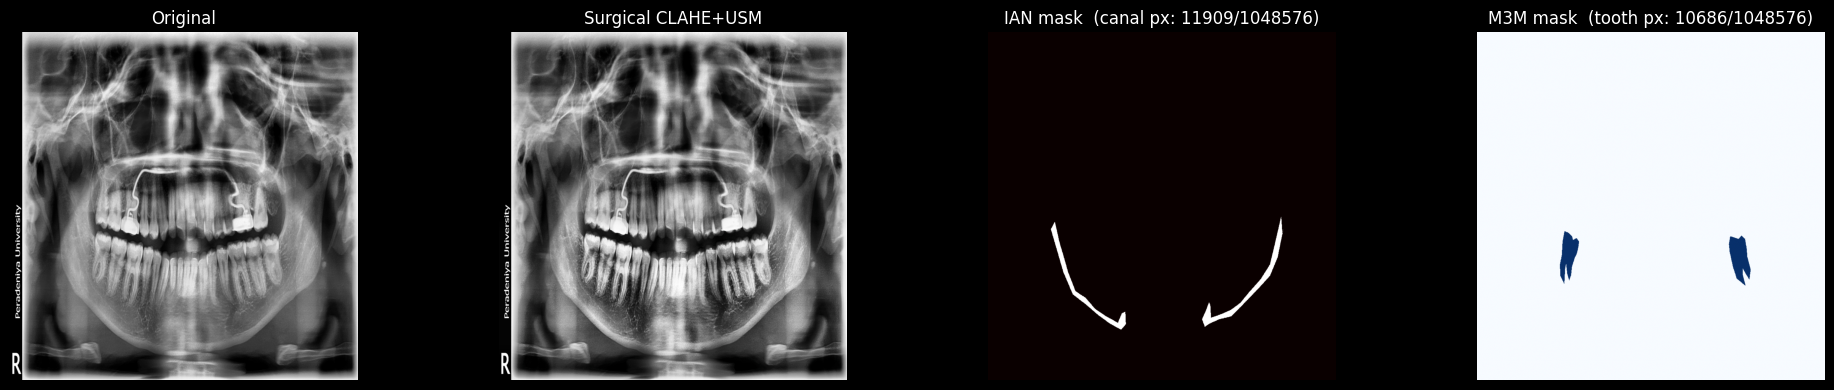

IAN canal: 1.136% of pixels  → class imbalance ratio ~1:88
M3M tooth: 1.02% of pixels  → class imbalance ratio ~1:98

Note: IAN extreme imbalance → Dice loss is essential (pure BCE would predict all-zero)


In [7]:
def coco_polygons_to_mask(annotations, cat_id, img_h, img_w, target_size):
    """
    Render all polygons of category `cat_id` from `annotations` into a
    binary mask of shape (target_size, target_size).

    Uses NEAREST interpolation on resize to avoid blurring mask edges.
    Returns float32 mask in [0, 1].
    """
    mask = np.zeros((img_h, img_w), dtype=np.uint8)
    for ann in annotations:
        if ann['category_id'] != cat_id:
            continue
        for seg in ann.get('segmentation', []):
            if len(seg) < 6:
                continue
            pts = np.array(seg, dtype=np.float32).reshape(-1, 2).astype(np.int32)
            cv2.fillPoly(mask, [pts], 1)
    if target_size != img_h or target_size != img_w:
        mask = cv2.resize(mask, (target_size, target_size),
                          interpolation=cv2.INTER_NEAREST)
    return mask.astype(np.float32)


# Quick sanity check — render one IAN mask and display
ian_sample = next(m for m in SPLITS['train']
                  if any(a['category_id']==IAN_CAT_ID for a in img_to_anns[m['id']]))
img_bgr  = cv2.imread(os.path.join(IMAGE_DIR, ian_sample['file_name']))
img_proc = surgical_clahe_unsharp(img_bgr)
ian_mask = coco_polygons_to_mask(
    img_to_anns[ian_sample['id']], IAN_CAT_ID,
    ian_sample['height'], ian_sample['width'], IMG_SIZE
)
m3m_mask = coco_polygons_to_mask(
    img_to_anns[ian_sample['id']], M3M_CAT_ID,
    ian_sample['height'], ian_sample['width'], IMG_SIZE
)

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
img_rgb  = cv2.cvtColor(cv2.resize(img_bgr,  (IMG_SIZE, IMG_SIZE)), cv2.COLOR_BGR2RGB)
proc_rgb = cv2.cvtColor(cv2.resize(img_proc, (IMG_SIZE, IMG_SIZE)), cv2.COLOR_BGR2RGB)
axes[0].imshow(img_rgb);   axes[0].set_title('Original');          axes[0].axis('off')
axes[1].imshow(proc_rgb);  axes[1].set_title('Surgical CLAHE+USM'); axes[1].axis('off')
axes[2].imshow(ian_mask, cmap='hot', vmin=0, vmax=1)
axes[2].set_title(f'IAN mask  (canal px: {ian_mask.sum():.0f}/{IMG_SIZE**2})'); axes[2].axis('off')
axes[3].imshow(m3m_mask, cmap='Blues', vmin=0, vmax=1)
axes[3].set_title(f'M3M mask  (tooth px: {m3m_mask.sum():.0f}/{IMG_SIZE**2})'); axes[3].axis('off')
plt.tight_layout()
plt.savefig(os.path.join(WORK_DIR, 'mask_sanity.png'), dpi=120, bbox_inches='tight')
plt.show()

ian_pct = ian_mask.mean() * 100
m3m_pct = m3m_mask.mean() * 100
print(f'IAN canal: {ian_pct:.3f}% of pixels  → class imbalance ratio ~1:{100/ian_pct:.0f}')
print(f'M3M tooth: {m3m_pct:.2f}% of pixels  → class imbalance ratio ~1:{100/m3m_pct:.0f}')
print('\nNote: IAN extreme imbalance → Dice loss is essential (pure BCE would predict all-zero)')

## 7. PyTorch Dataset

One unified Dataset class that returns `(image, ian_mask, m3m_mask)`.  
Augmentations applied consistently to image and both masks.

In [8]:
# Augmentation pipelines
# IMPORTANT: ToFloat(max_value=255) → values in [0,1] before Normalize
TRAIN_TRANSFORM = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=5, p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.1, contrast_limit=0.1, p=0.4),
    A.GaussNoise(var_limit=(5.0, 20.0), p=0.3),
    # A.Resize(IMG_SIZE, IMG_SIZE), # Removed, as image and masks are now pre-resized
    A.Normalize(mean=(0.485, 0.456, 0.406),   # ImageNet stats (matches ResNet-50 pretraining)
                std =(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

VAL_TRANSFORM = A.Compose([
    # A.Resize(IMG_SIZE, IMG_SIZE), # Removed, as image and masks are now pre-resized
    A.Normalize(mean=(0.485, 0.456, 0.406),
                std =(0.229, 0.224, 0.225)),
    ToTensorV2(),
])


class DentalDataset(Dataset):
    """
    Returns (image_tensor [3,H,W], ian_mask [1,H,W], m3m_mask [1,H,W]).
    Image is preprocessed with surgical CLAHE+Unsharp before augmentation.
    Masks are rendered at IMG_SIZE×IMG_SIZE from COCO polygons.
    """
    def __init__(self, img_infos, image_dir, img_to_anns,
                 ian_cat_id, m3m_cat_id, transform, preprocess=True):
        self.img_infos  = img_infos
        self.image_dir  = image_dir
        self.img_to_anns = img_to_anns
        self.ian_cat_id = ian_cat_id
        self.m3m_cat_id = m3m_cat_id
        self.transform  = transform
        self.preprocess = preprocess

    def __len__(self):
        return len(self.img_infos)

    def __getitem__(self, idx):
        info    = self.img_infos[idx]
        img_bgr = cv2.imread(os.path.join(self.image_dir, info['file_name']))

        if self.preprocess:
            img_bgr = surgical_clahe_unsharp(img_bgr)

        # Convert BGR → RGB for albumentations / ImageNet normalisation
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        # Resize image to IMG_SIZE before passing to albumentations for shape consistency
        img_rgb_resized = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)

        anns    = self.img_to_anns.get(info['id'], [])
        h, w    = info['height'], info['width']

        # coco_polygons_to_mask already resizes to IMG_SIZE
        ian_mask = coco_polygons_to_mask(anns, self.ian_cat_id, h, w, IMG_SIZE)
        m3m_mask = coco_polygons_to_mask(anns, self.m3m_cat_id, h, w, IMG_SIZE)

        # Albumentations expects HWC image and HW masks
        # Use additional_targets to keep masks in sync with augmentation
        aug = self.transform(
            image=img_rgb_resized, # Use the pre-resized image
            masks=[ian_mask, m3m_mask]   # both masks transformed identically
        )
        image    = aug['image']             # tensor [3, H, W]
        ian_out  = aug['masks'][0].unsqueeze(0)  # [1, H, W]
        m3m_out  = aug['masks'][1].unsqueeze(0)  # [1, H, W]

        return image, ian_out, m3m_out


train_ds = DentalDataset(SPLITS['train'], IMAGE_DIR, img_to_anns,
                         IAN_CAT_ID, M3M_CAT_ID, TRAIN_TRANSFORM)
val_ds   = DentalDataset(SPLITS['val'],   IMAGE_DIR, img_to_anns,
                         IAN_CAT_ID, M3M_CAT_ID, VAL_TRANSFORM)
test_ds  = DentalDataset(SPLITS['test'],  IMAGE_DIR, img_to_anns,
                         IAN_CAT_ID, M3M_CAT_ID, VAL_TRANSFORM)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=0, pin_memory=False)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=0, pin_memory=False)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=0, pin_memory=False)

print(f'✓ Datasets ready')
print(f'  Train batches: {len(train_loader)} × batch {BATCH_SIZE}')
print(f'  Val   batches: {len(val_loader)}')
print(f'  Test  batches: {len(test_loader)}')

# Quick shape check
img_b, ian_b, m3m_b = next(iter(train_loader))
print(f'\nBatch shapes: image={tuple(img_b.shape)}  ian={tuple(ian_b.shape)}  m3m={tuple(m3m_b.shape)}')

✓ Datasets ready
  Train batches: 168 × batch 2
  Val   batches: 36
  Test  batches: 37


E:\IIT\NEW_FYP\AMD\.venv\Lib\site-packages\albumentations\core\validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
C:\Users\minud\AppData\Local\Temp\ipykernel_17664\2264634305.py:7: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(5.0, 20.0), p=0.3),



Batch shapes: image=(2, 3, 1024, 1024)  ian=(2, 1, 1024, 1024)  m3m=(2, 1, 1024, 1024)


## 8. Loss Function: Dice + BCE

**Why Dice loss?**  
The IAN canal occupies ~0.1–0.5% of pixels. Pure BCE would achieve 99.5% accuracy by predicting  
all background — Dice loss directly measures mask overlap regardless of class imbalance.

- **IAN model**: `0.6 × Dice + 0.4 × BCE` — Dice weighted higher (extreme imbalance)  
- **M3M model**: `0.4 × Dice + 0.6 × BCE` — BCE weighted higher (less imbalanced, larger regions)

In [9]:
class DiceBCELoss(nn.Module):
    """
    Combined Dice + Binary Cross-Entropy loss.

    Args:
        dice_weight : weight on Dice component (1 - dice_weight goes to BCE)
        smooth      : Laplace smoothing to avoid log(0) and div-by-zero
    """
    def __init__(self, dice_weight=0.6, smooth=1.0):
        super().__init__()
        self.dice_w = dice_weight
        self.bce_w  = 1.0 - dice_weight
        self.smooth = smooth
        self.bce    = nn.BCEWithLogitsLoss()

    def dice_loss(self, logits, targets):
        probs  = torch.sigmoid(logits)
        # Flatten spatial dims
        p      = probs.view(probs.size(0), -1)
        t      = targets.view(targets.size(0), -1)
        inter  = (p * t).sum(dim=1)
        denom  = p.sum(dim=1) + t.sum(dim=1) + self.smooth
        return 1.0 - (2.0 * inter + self.smooth) / denom

    def forward(self, logits, targets):
        dice = self.dice_loss(logits, targets).mean()
        bce  = self.bce(logits, targets)
        return self.dice_w * dice + self.bce_w * bce


IAN_CRITERION = DiceBCELoss(dice_weight=0.6)  # heavier Dice for sparse canal
M3M_CRITERION = DiceBCELoss(dice_weight=0.4)  # balanced for larger tooth regions

print('✓ Loss functions defined')
print('  IAN: 0.6×Dice + 0.4×BCE')
print('  M3M: 0.4×Dice + 0.6×BCE')

✓ Loss functions defined
  IAN: 0.6×Dice + 0.4×BCE
  M3M: 0.4×Dice + 0.6×BCE


## 9. Build Two U-Net + ResNet-50 Models

One binary segmentation model per class.  
`segmentation_models_pytorch` handles the ResNet-50 backbone + U-Net decoder with a single call.

In [10]:
def build_unet(encoder='resnet50', pretrained='imagenet', in_ch=3, out_ch=1):
    return smp.Unet(
        encoder_name          = encoder,
        encoder_weights       = pretrained,
        in_channels           = in_ch,
        classes               = out_ch,
        activation            = None,
        decoder_use_batchnorm = True,
    )



# Build IAN model only for now — don't build m3m_model yet
ian_model = build_unet().to(DEVICE)

ian_params = sum(p.numel() for p in ian_model.parameters()) / 1e6
print(f'U-Net+ResNet50 parameters : {ian_params:.1f}M per model')
print(f'Running on: {DEVICE}')

# VRAM check skipped — torch.cuda.memory_allocated() not available for DirectML
# RX 6800 has 16 GB VRAM which is sufficient; reduce BATCH_SIZE if OOM occurs

U-Net+ResNet50 parameters : 32.5M per model
Running on: privateuseone:0


## 10. Training Utilities: Metrics, Scheduler, Early Stopping

In [11]:
def dice_score(preds_prob, targets, threshold=0.5, smooth=1.0):
    """Batch-averaged Dice coefficient. preds_prob: sigmoid output in [0,1]."""
    p = (preds_prob > threshold).float().view(preds_prob.size(0), -1)
    t = targets.view(targets.size(0), -1)
    inter = (p * t).sum(dim=1)
    denom = p.sum(dim=1) + t.sum(dim=1) + smooth
    return ((2.0 * inter + smooth) / denom).mean().item()


def iou_score(preds_prob, targets, threshold=0.5, smooth=1.0):
    """Batch-averaged IoU (Jaccard index)."""
    p = (preds_prob > threshold).float().view(preds_prob.size(0), -1)
    t = targets.view(targets.size(0), -1)
    inter = (p * t).sum(dim=1)
    union = p.sum(dim=1) + t.sum(dim=1) - inter + smooth
    return ((inter + smooth) / union).mean().item()


def precision_recall(preds_prob, targets, threshold=0.5):
    """Returns (precision, recall) averaged over batch."""
    p = (preds_prob > threshold).float().view(preds_prob.size(0), -1)
    t = targets.view(targets.size(0), -1)
    tp = (p * t).sum(dim=1)
    fp = (p * (1-t)).sum(dim=1)
    fn = ((1-p) * t).sum(dim=1)
    prec = (tp / (tp + fp + 1e-8)).mean().item()
    rec  = (tp / (tp + fn + 1e-8)).mean().item()
    return prec, rec


class EarlyStopping:
    """Stop if val Dice doesn't improve after `patience` epochs."""
    def __init__(self, patience=20, min_delta=1e-4):
        self.patience   = patience
        self.min_delta  = min_delta
        self.best_score = None
        self.counter    = 0
        self.triggered  = False

    def step(self, score):
        if self.best_score is None or score > self.best_score + self.min_delta:
            self.best_score = score
            self.counter    = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.triggered = True
        return self.triggered


print('✓ Metrics and utilities defined')

✓ Metrics and utilities defined


## 11. Training Loop

In [12]:
def train_one_model(model, criterion, train_loader, val_loader,
                    name, save_dir, epochs=EPOCHS, lr=LR,
                    mask_idx=0):   # mask_idx: 0=IAN, 1=M3M
    """
    Full training loop for one binary U-Net model.

    mask_idx=0 → reads ian_mask from batch
    mask_idx=1 → reads m3m_mask from batch

    Uses:
    - AdamW optimiser (weight_decay=1e-4)
    - CosineAnnealingLR (T_max=epochs, eta_min=LR_MIN)
    - EarlyStopping (patience=25)
    - Saves best model by val Dice
    """
    optimizer  = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler  = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=epochs, eta_min=LR_MIN)
    stopper    = EarlyStopping(patience=25)
    best_dice  = 0.0
    save_path  = os.path.join(save_dir, f'{name}_best.pth')
    history    = {'train_loss': [], 'val_loss': [], 'val_dice': [], 'val_iou': []}

    print(f'\n{"="*60}')
    print(f'Training: {name} | {epochs} epochs | lr={lr}')
    print(f'{"="*60}')

    for epoch in range(1, epochs + 1):
        # ── Train ──────────────────────────────────────────────────────────────
        model.train()
        train_loss = 0.0
        for batch in train_loader:
            imgs, ian_masks, m3m_masks = batch
            masks = [ian_masks, m3m_masks][mask_idx]
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
            optimizer.zero_grad()
            logits = model(imgs)
            loss   = criterion(logits, masks)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
        train_loss /= len(train_loader)

        # ── Validate ───────────────────────────────────────────────────────────
        model.eval()
        val_loss, val_dice, val_iou = 0.0, 0.0, 0.0
        with torch.no_grad():
            for batch in val_loader:
                imgs, ian_masks, m3m_masks = batch
                masks = [ian_masks, m3m_masks][mask_idx]
                imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
                logits = model(imgs)
                val_loss += criterion(logits, masks).item()
                probs     = torch.sigmoid(logits)
                val_dice += dice_score(probs, masks)
                val_iou  += iou_score(probs, masks)
        val_loss /= len(val_loader)
        val_dice /= len(val_loader)
        val_iou  /= len(val_loader)

        scheduler.step()

        # ── Log ────────────────────────────────────────────────────────────────
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_dice'].append(val_dice)
        history['val_iou'].append(val_iou)

        if val_dice > best_dice:
            best_dice = val_dice
            torch.save(model.state_dict(), save_path)
            tag = '  ✓ saved'
        else:
            tag = ''

        if epoch % 10 == 0 or epoch == 1:
            lr_now = optimizer.param_groups[0]['lr']
            print(f'  Ep {epoch:3d}/{epochs} | '
                  f'loss {train_loss:.4f}→{val_loss:.4f} | '
                  f'Dice {val_dice:.4f} | IoU {val_iou:.4f} | '
                  f'lr {lr_now:.2e}{tag}')

        if stopper.step(val_dice):
            print(f'  Early stop at epoch {epoch} (patience=25, best Dice={best_dice:.4f})')
            break

    print(f'\n  Best val Dice: {best_dice:.4f} → {save_path}')
    return history, save_path

print('✓ Training loop defined')

✓ Training loop defined


## 12. Train IAN Canal Model

**Expected time: ~45–60 min on T4** (150 epochs, 268 images, batch=8)

In [13]:
ian_model = build_unet().to(DEVICE)

ian_history, ian_best_path = train_one_model(
    model        = ian_model,
    criterion    = IAN_CRITERION,
    train_loader = train_loader,
    val_loader   = val_loader,
    name         = 'unet_ian',
    save_dir     = MODEL_SAVE_DIR,
    epochs       = EPOCHS,
    lr           = LR,
    mask_idx     = 0,   # 0 = IAN canal
)


Training: unet_ian | 150 epochs | lr=0.0001


E:\IIT\NEW_FYP\AMD\.venv\Lib\site-packages\torch\nn\functional.py:3244: UserWarning: The operator 'aten::log_sigmoid_forward' is not currently supported on the DML backend and will fall back to run on the CPU. This may have performance implications. (Triggered internally at C:\__w\1\s\pytorch-directml-plugin\torch_directml\csrc\dml\dml_cpu_fallback.cpp:17.)
  return torch.binary_cross_entropy_with_logits(input, target, weight, pos_weight, reduction_enum)


  Ep   1/150 | loss 0.7095→0.6072 | Dice 0.4920 | IoU 0.3328 | lr 1.00e-04  ✓ saved
  Ep  10/150 | loss 0.2297→0.2151 | Dice 0.6884 | IoU 0.5396 | lr 9.89e-05  ✓ saved
  Ep  20/150 | loss 0.1989→0.2050 | Dice 0.6914 | IoU 0.5435 | lr 9.57e-05
  Ep  30/150 | loss 0.1777→0.2147 | Dice 0.6756 | IoU 0.5257 | lr 9.05e-05
  Ep  40/150 | loss 0.1625→0.2065 | Dice 0.6879 | IoU 0.5396 | lr 8.36e-05
  Ep  50/150 | loss 0.1493→0.2077 | Dice 0.6858 | IoU 0.5376 | lr 7.53e-05
  Ep  60/150 | loss 0.1396→0.2082 | Dice 0.6853 | IoU 0.5368 | lr 6.58e-05
  Early stop at epoch 68 (patience=25, best Dice=0.6959)

  Best val Dice: 0.6959 → E:\IIT\NEW_FYP\MODELS\UNet_ResNet50\unet_ian_best.pth


## 13. Train M3M Model

**Expected time: ~45–60 min on T4**

In [14]:
# Free IAN model from VRAM before loading M3M
# import gc
# del ian_model
# gc.collect()

m3m_model = build_unet().to(DEVICE)

In [15]:
m3m_model = build_unet().to(DEVICE)

m3m_history, m3m_best_path = train_one_model(
    model        = m3m_model,
    criterion    = M3M_CRITERION,
    train_loader = train_loader,
    val_loader   = val_loader,
    name         = 'unet_m3m',
    save_dir     = MODEL_SAVE_DIR,
    epochs       = EPOCHS,
    lr           = LR,
    mask_idx     = 1,   # 1 = M3M tooth
)


Training: unet_m3m | 150 epochs | lr=0.0001
  Ep   1/150 | loss 0.5326→0.4276 | Dice 0.7441 | IoU 0.6055 | lr 1.00e-04  ✓ saved
  Ep  10/150 | loss 0.0743→0.0792 | Dice 0.8490 | IoU 0.7636 | lr 9.89e-05
  Ep  20/150 | loss 0.0593→0.0607 | Dice 0.8754 | IoU 0.7964 | lr 9.57e-05  ✓ saved
  Ep  30/150 | loss 0.0545→0.0624 | Dice 0.8706 | IoU 0.7907 | lr 9.05e-05
  Ep  40/150 | loss 0.0524→0.0611 | Dice 0.8725 | IoU 0.7930 | lr 8.36e-05
  Ep  50/150 | loss 0.0510→0.0609 | Dice 0.8728 | IoU 0.7928 | lr 7.53e-05
  Ep  60/150 | loss 0.0517→0.0608 | Dice 0.8737 | IoU 0.7947 | lr 6.58e-05
  Early stop at epoch 64 (patience=25, best Dice=0.8794)

  Best val Dice: 0.8794 → E:\IIT\NEW_FYP\MODELS\UNet_ResNet50\unet_m3m_best.pth


## 14. Training Curves

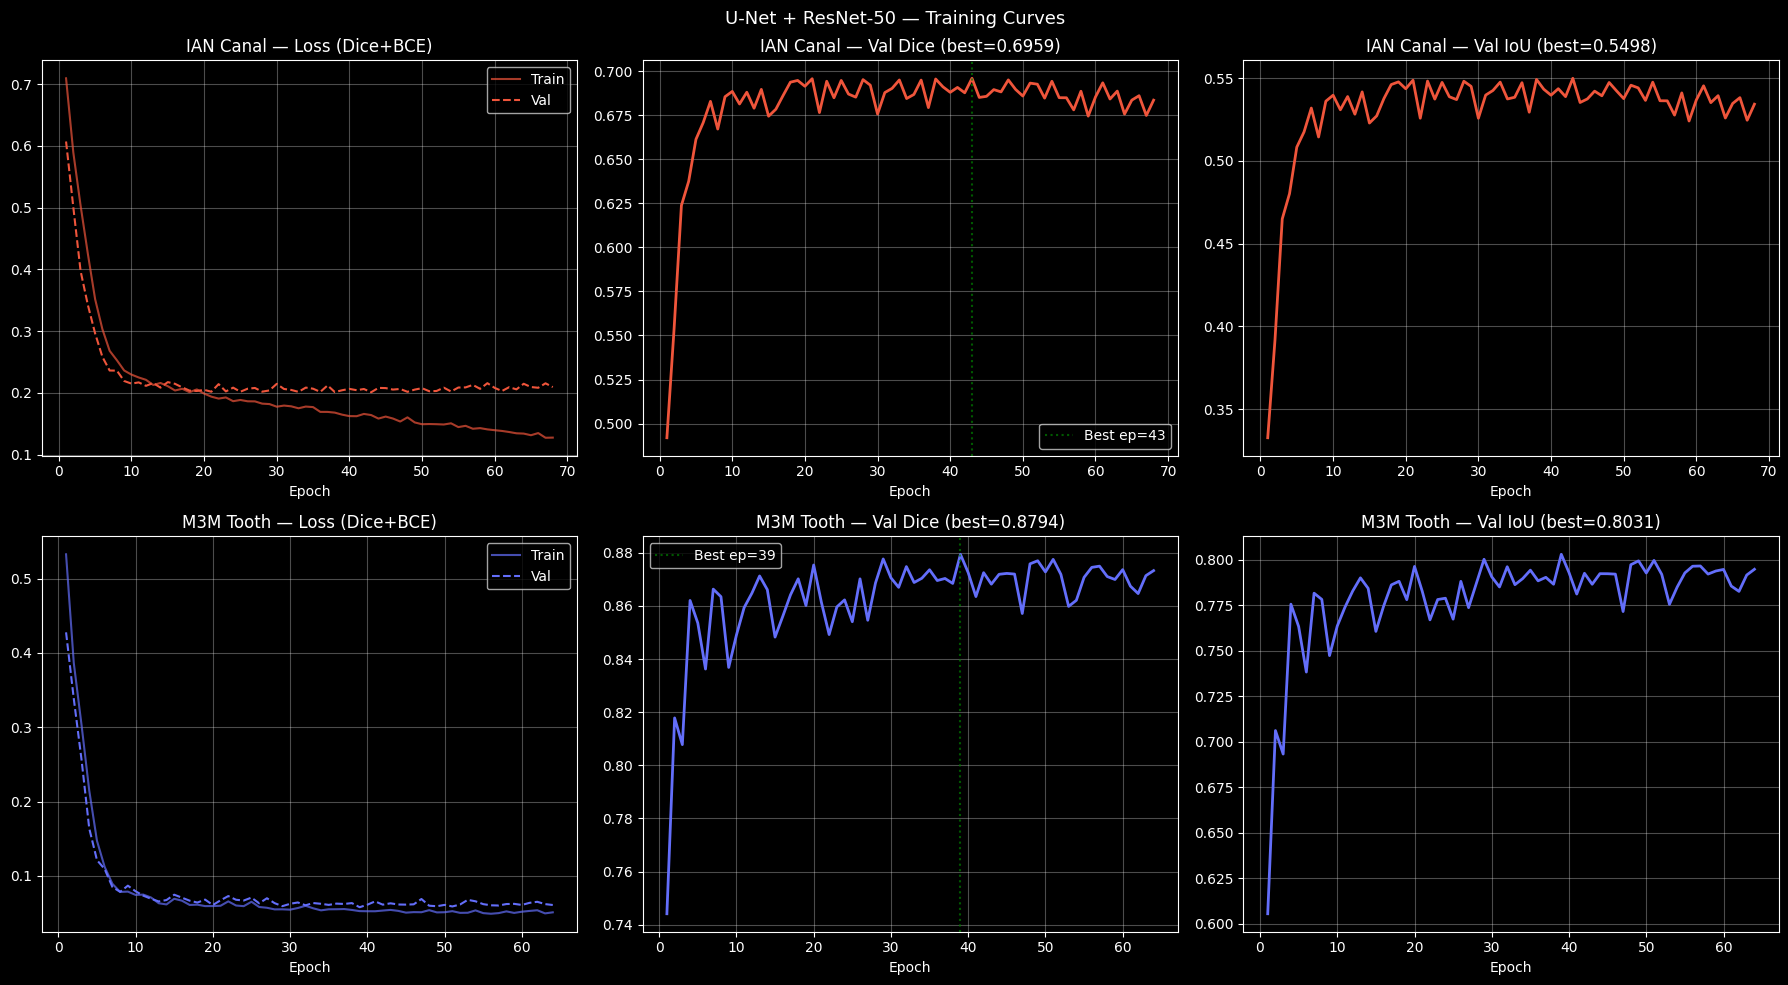

✓ Saved: E:\IIT\NEW_FYP\MODELS\UNet_ResNet50\training_curves.png


In [16]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('U-Net + ResNet-50 — Training Curves', fontsize=13)

configs = [
    (ian_history, 'IAN Canal',  '#EF553B', axes[0]),
    (m3m_history, 'M3M Tooth',  '#636EFA', axes[1]),
]

for hist, label, color, row_axes in configs:
    epochs_x = range(1, len(hist['val_dice']) + 1)

    row_axes[0].plot(epochs_x, hist['train_loss'], color=color, linewidth=1.5, alpha=0.7, label='Train')
    row_axes[0].plot(epochs_x, hist['val_loss'],   color=color, linewidth=1.5, linestyle='--', label='Val')
    row_axes[0].set_title(f'{label} — Loss (Dice+BCE)')
    row_axes[0].set_xlabel('Epoch'); row_axes[0].legend(); row_axes[0].grid(alpha=0.3)

    row_axes[1].plot(epochs_x, hist['val_dice'], color=color, linewidth=2)
    best_ep = np.argmax(hist['val_dice']) + 1
    best_d  = max(hist['val_dice'])
    row_axes[1].axvline(best_ep, color='green', linestyle=':', alpha=0.7, label=f'Best ep={best_ep}')
    row_axes[1].set_title(f'{label} — Val Dice (best={best_d:.4f})')
    row_axes[1].set_xlabel('Epoch'); row_axes[1].legend(); row_axes[1].grid(alpha=0.3)

    row_axes[2].plot(epochs_x, hist['val_iou'], color=color, linewidth=2)
    best_iou = max(hist['val_iou'])
    row_axes[2].set_title(f'{label} — Val IoU (best={best_iou:.4f})')
    row_axes[2].set_xlabel('Epoch'); row_axes[2].grid(alpha=0.3)

plt.tight_layout()
curve_path = os.path.join(MODEL_SAVE_DIR, 'training_curves.png')
plt.savefig(curve_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'✓ Saved: {curve_path}')

## 15. Test Set Evaluation

Evaluates both models on the held-out test split using:
- **Dice coefficient** (primary metric — mask quality)
- **IoU** (Jaccard index)
- **Precision / Recall**
- **mAP50-95 approximation** — threshold sweep at IoU 0.50, 0.55, ..., 0.95, for direct comparison with YOLO results

In [17]:
def compute_map_approx(model, loader, mask_idx, iou_thresholds=None):
    """
    Approximates mAP50-95 for a binary segmentation model via a threshold sweep.

    Method:
    - For each IoU threshold t in [0.50, 0.55, ..., 0.95]:
        - A predicted mask 'detects' a ground-truth mask if their IoU >= t
        - Average Precision at that threshold = TP / (TP + FP + FN)
    - mAP50-95 = mean of AP over all thresholds (matching COCO protocol)

    Note: Because U-Net produces one mask per image (not multiple instances),
    this gives per-image precision, not multi-instance mAP. Still provides
    a direct comparable number to YOLO's mAP50-95.
    """
    if iou_thresholds is None:
        iou_thresholds = np.arange(0.50, 1.00, 0.05)

    model.eval()
    aps = []

    with torch.no_grad():
        for t in iou_thresholds:
            tp = fp = fn = 0
            for batch in loader:
                imgs, ian_masks, m3m_masks = batch
                masks = [ian_masks, m3m_masks][mask_idx]
                imgs  = imgs.to(DEVICE)
                probs = torch.sigmoid(model(imgs)).cpu()
                for i in range(probs.size(0)):
                    pred_bin = (probs[i] > 0.5).float()
                    gt       = masks[i]
                    # Compute IoU between predicted and GT mask
                    inter = (pred_bin * gt).sum().item()
                    union = (pred_bin + gt - pred_bin * gt).sum().item()
                    img_iou = (inter + 1e-8) / (union + 1e-8)
                    has_gt   = gt.sum().item() > 0
                    has_pred = pred_bin.sum().item() > 0
                    if img_iou >= t:
                        tp += 1
                    elif has_pred and not has_gt:
                        fp += 1
                    elif not has_pred and has_gt:
                        fn += 1
            ap = (tp + 1e-8) / (tp + fp + fn + 1e-8)
            aps.append(ap)

    return float(np.mean(aps)), float(aps[0])  # (mAP50-95, mAP50)


def full_evaluation(model, loader, mask_idx, name):
    """Compute Dice, IoU, Precision, Recall, mAP50, mAP50-95 on loader."""
    model.eval()
    dice_sum = iou_sum = prec_sum = rec_sum = 0.0
    n = 0
    with torch.no_grad():
        for batch in tqdm(loader, desc=f'Evaluating {name}'):
            imgs, ian_masks, m3m_masks = batch
            masks = [ian_masks, m3m_masks][mask_idx]
            imgs  = imgs.to(DEVICE)
            probs = torch.sigmoid(model(imgs)).cpu()
            dice_sum += dice_score(probs, masks)
            iou_sum  += iou_score(probs, masks)
            pr, re    = precision_recall(probs, masks)
            prec_sum += pr; rec_sum += re
            n += 1

    map5095, map50 = compute_map_approx(model, loader, mask_idx)

    return {
        'Dice':      dice_sum / n,
        'IoU':       iou_sum  / n,
        'Precision': prec_sum / n,
        'Recall':    rec_sum  / n,
        'mAP50':     map50,
        'mAP50-95':  map5095,
    }


# Load best weights
# Load best weights — map to CPU first, then move to DirectML device
ian_model.load_state_dict(torch.load(ian_best_path, map_location='cpu'))
m3m_model.load_state_dict(torch.load(m3m_best_path, map_location='cpu'))
ian_model = ian_model.to(DEVICE)
m3m_model = m3m_model.to(DEVICE)

print('Running test set evaluation...')
ian_test_metrics = full_evaluation(ian_model, test_loader, mask_idx=0, name='IAN')
m3m_test_metrics = full_evaluation(m3m_model, test_loader, mask_idx=1, name='M3M')

print('\n' + '='*60)
print('TEST SET METRICS — U-Net + ResNet-50')
print('='*60)
for label, metrics, target_flag in [
    ('IAN Canal', ian_test_metrics, True),
    ('M3M Tooth',  m3m_test_metrics, False),
]:
    print(f'\n  {label}:')
    for k, v in metrics.items():
        flag = '  ← PRIMARY TARGET' if k == 'mAP50-95' and target_flag else ''
        print(f'    {k:<14}: {v:.4f}{flag}')
print('='*60)

C:\Users\minud\AppData\Local\Temp\ipykernel_17664\1493660000.py:81: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ian_model.load_state_dict(torch.load(ian_best_path, map_loc

Running test set evaluation...


Evaluating M3M: 100%|██████████| 37/37 [00:10<00:00,  3.57it/s]



TEST SET METRICS — U-Net + ResNet-50

  IAN Canal:
    Dice          : 0.6771
    IoU           : 0.5272
    Precision     : 0.6352
    Recall        : 0.7463
    mAP50         : 0.9815
    mAP50-95      : 0.5082  ← PRIMARY TARGET

  M3M Tooth:
    Dice          : 0.8816
    IoU           : 0.7970
    Precision     : 0.8914
    Recall        : 0.8853
    mAP50         : 1.0000
    mAP50-95      : 1.0000


## 16. Comparison Table — All Models

                       Model  IAN mAP50  IAN mAP50-95  M3M mAP50-95  All mAP50-95
            YOLOv8s baseline     0.3549        0.0651        0.5918        0.3285
    YOLO11s + Surgical CLAHE     0.8329        0.2366        0.6776        0.4571
U-Net + ResNet-50 (this run)     0.9815        0.5082        1.0000        0.7541


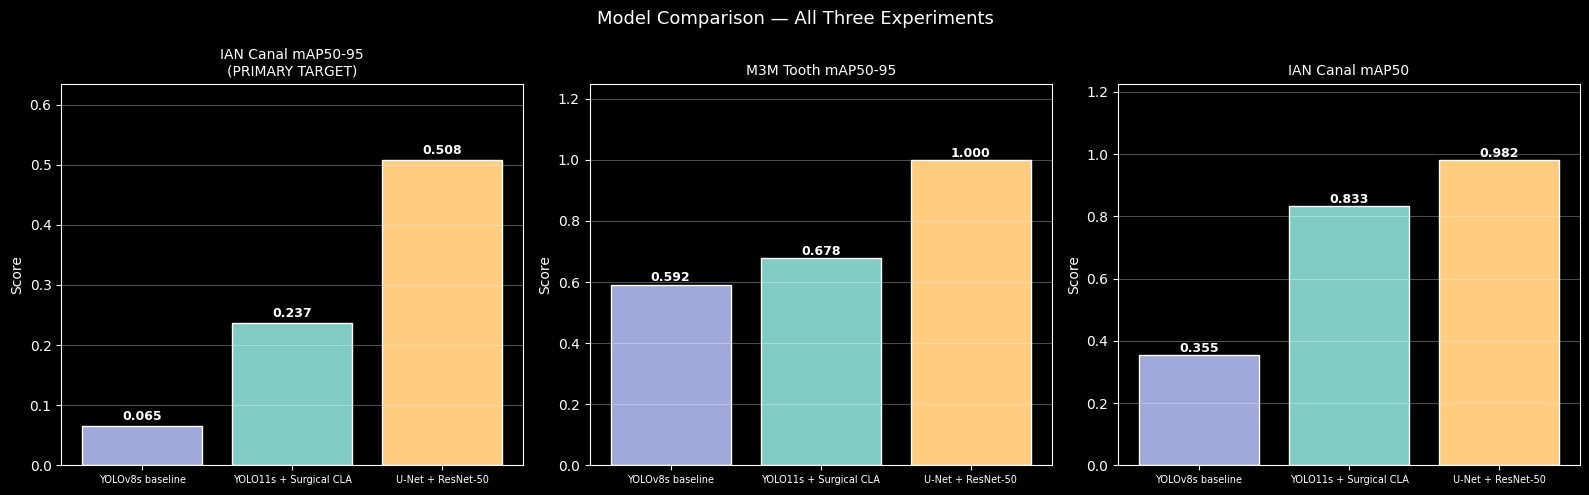

✓ Saved: E:\IIT\NEW_FYP\MODELS\UNet_ResNet50\model_comparison.png


In [18]:
comparison = pd.DataFrame([
    {
        'Model':        'YOLOv8s baseline',
        'IAN mAP50':    0.3549,
        'IAN mAP50-95': 0.0651,
        'M3M mAP50-95': 0.5918,
        'All mAP50-95': 0.3285,
    },
    {
        'Model':        'YOLO11s + Surgical CLAHE',
        'IAN mAP50':    0.8329,
        'IAN mAP50-95': 0.2366,
        'M3M mAP50-95': 0.6776,
        'All mAP50-95': 0.4571,
    },
    {
        'Model':        'U-Net + ResNet-50 (this run)',
        'IAN mAP50':    round(ian_test_metrics['mAP50'],    4),
        'IAN mAP50-95': round(ian_test_metrics['mAP50-95'], 4),
        'M3M mAP50-95': round(m3m_test_metrics['mAP50-95'], 4),
        'All mAP50-95': round((ian_test_metrics['mAP50-95'] + m3m_test_metrics['mAP50-95']) / 2, 4),
    },
])

print(comparison.to_string(index=False))
comparison.to_csv(os.path.join(MODEL_SAVE_DIR, 'model_comparison.csv'), index=False)

# Visual bar chart
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Model Comparison — All Three Experiments', fontsize=13)
colors = ['#9FA8DA', '#80CBC4', '#FFCC80']
models = comparison['Model'].tolist()

for ax, col, title in [
    (axes[0], 'IAN mAP50-95', 'IAN Canal mAP50-95\n(PRIMARY TARGET)'),
    (axes[1], 'M3M mAP50-95', 'M3M Tooth mAP50-95'),
    (axes[2], 'IAN mAP50',    'IAN Canal mAP50'),
]:
    vals = comparison[col].tolist()
    bars = ax.bar([m.split(' (')[0][:22] for m in models], vals, color=colors, edgecolor='white')
    ax.set_title(title, fontsize=10)
    ax.set_ylim(0, max(vals) * 1.25)
    ax.set_ylabel('Score')
    ax.tick_params(axis='x', labelsize=7)
    ax.grid(axis='y', alpha=0.3)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                f'{v:.3f}', ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
cmp_path = os.path.join(MODEL_SAVE_DIR, 'model_comparison.png')
plt.savefig(cmp_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'✓ Saved: {cmp_path}')

## 17. Qualitative Results — Predicted Masks on Test Images

For each test image: original, ground truth IAN mask, predicted IAN mask, overlay.

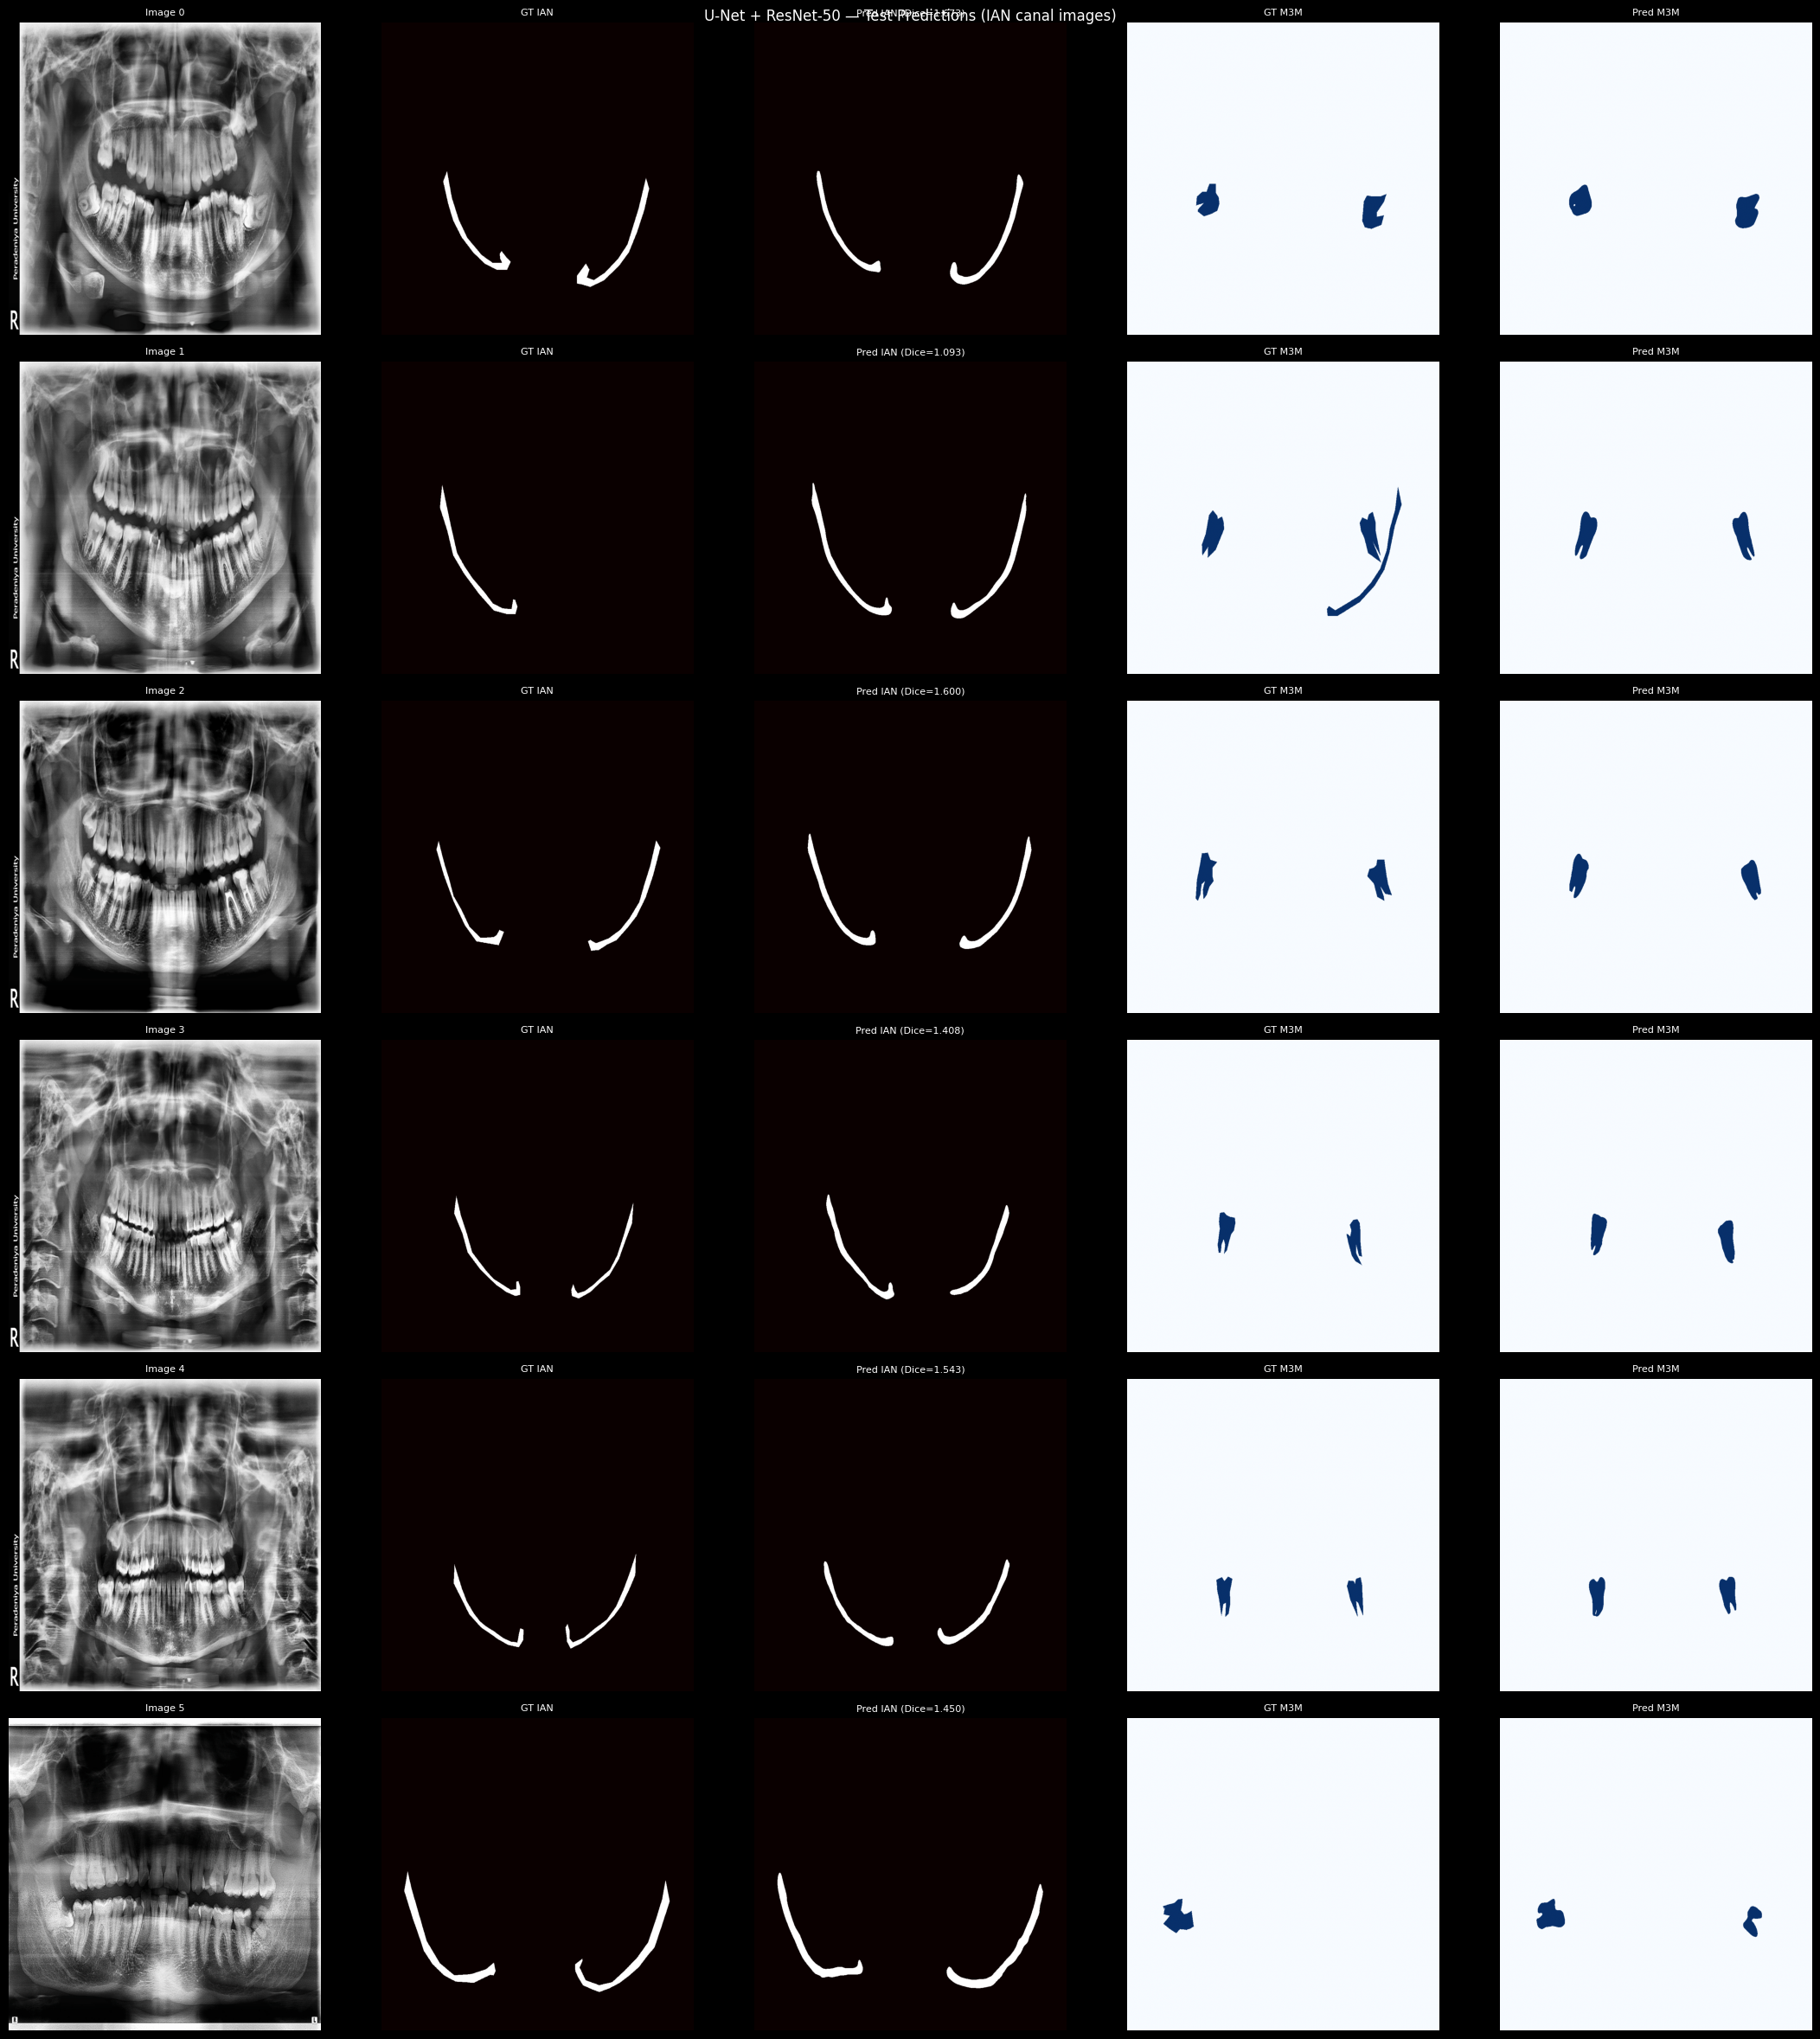

✓ Qualitative results saved


In [19]:
def visualise_predictions(ian_model, m3m_model, dataset, n=6, save_path=None):
    """Show side-by-side GT vs predicted masks for n test images with IAN canal."""
    ian_model.eval(); m3m_model.eval()

    # Pick images that have IAN canal ground truth
    ian_indices = [
        i for i, info in enumerate(dataset.img_infos)
        if any(a['category_id'] == IAN_CAT_ID
               for a in dataset.img_to_anns.get(info['id'], []))
    ][:n]

    n = len(ian_indices)
    fig, axes = plt.subplots(n, 5, figsize=(22, 4*n))
    if n == 1: axes = axes[np.newaxis]
    cols = ['Original (preprocessed)', 'GT: IAN mask', 'Pred: IAN mask',
            'GT: M3M mask', 'Pred: M3M mask']
    for ax, col in zip(axes[0], cols):
        ax.set_title(col, fontsize=9, fontweight='bold')

    fig.suptitle('U-Net + ResNet-50 — Test Predictions (IAN canal images)', fontsize=12)

    for row, idx in enumerate(ian_indices):
        img_t, ian_gt, m3m_gt = dataset[idx]
        with torch.no_grad():
            ian_pred = torch.sigmoid(ian_model(img_t.unsqueeze(0).to(DEVICE))).squeeze().cpu().numpy()
            m3m_pred = torch.sigmoid(m3m_model(img_t.unsqueeze(0).to(DEVICE))).squeeze().cpu().numpy()

        # Denormalise image for display
        mean = np.array([0.485, 0.456, 0.406])
        std  = np.array([0.229, 0.224, 0.225])
        img_disp = img_t.permute(1,2,0).numpy() * std + mean
        img_disp = np.clip(img_disp, 0, 1)

        ian_gt_np  = ian_gt.squeeze().numpy()
        m3m_gt_np  = m3m_gt.squeeze().numpy()

        ian_dice = 2*(ian_pred > 0.5).astype(float) * ian_gt_np
        ian_d    = ian_dice.sum() / ((ian_pred > 0.5).sum() + ian_gt_np.sum() + 1e-8) * 2

        for ax, data, cmap, title in [
            (axes[row,0], img_disp,           None,      f'Image {idx}'),
            (axes[row,1], ian_gt_np,           'hot',     f'GT IAN'),
            (axes[row,2], (ian_pred>0.5).astype(float), 'hot', f'Pred IAN (Dice={ian_d:.3f})'),
            (axes[row,3], m3m_gt_np,           'Blues',   f'GT M3M'),
            (axes[row,4], (m3m_pred>0.5).astype(float), 'Blues', f'Pred M3M'),
        ]:
            if cmap:
                axes[row, [0,1,2,3,4].index(ax)].imshow(data, cmap=cmap, vmin=0, vmax=1) if False else None
                ax.imshow(data, cmap=cmap, vmin=0, vmax=1)
            else:
                ax.imshow(data)
            ax.set_title(title, fontsize=8)
            ax.axis('off')

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=120, bbox_inches='tight')
    plt.show()


visualise_predictions(
    ian_model, m3m_model, test_ds, n=6,
    save_path=os.path.join(MODEL_SAVE_DIR, 'test_predictions.png')
)
print('✓ Qualitative results saved')

## 18. IAN Canal Dice Distribution Across Test Set

Shows per-image Dice scores — important for clinical reliability.  
A model with high mean but high variance is less clinically trustworthy.

Per-image IAN analysis: 100%|██████████| 73/73 [00:10<00:00,  7.14it/s]


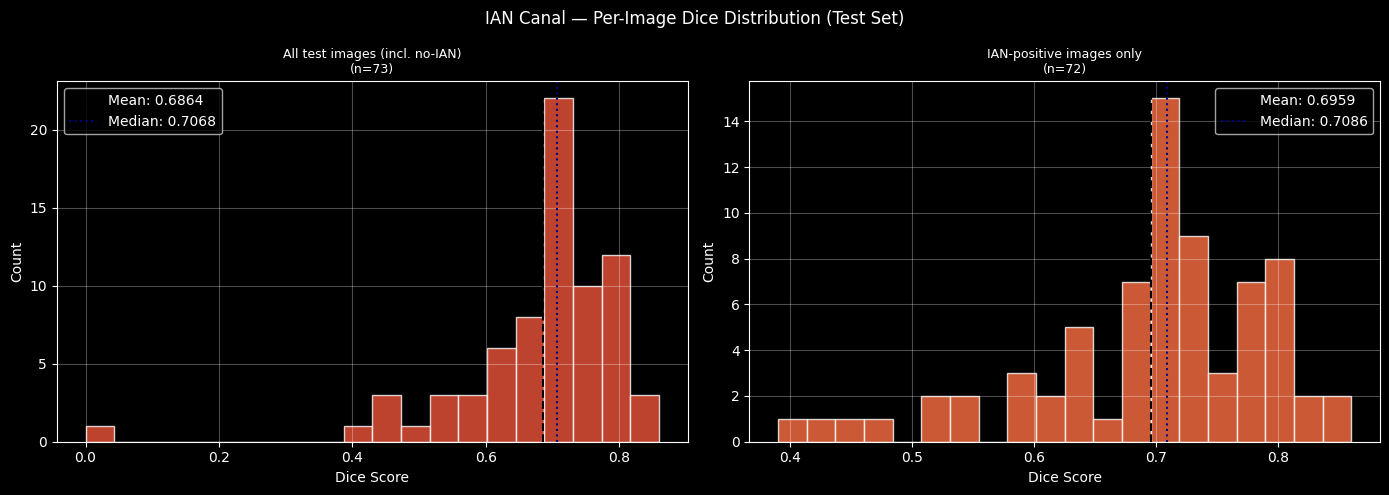

IAN Dice (all test)     : mean=0.6864  std=0.1267
IAN Dice (IAN-only)     : mean=0.6959  std=0.0983
IAN IoU  (all test)     : mean=0.5344
% test images Dice>0.5  : 94.4%
% test images Dice>0.7  : 61.1%


In [20]:
ian_model.eval()
per_image_dice = []
per_image_iou  = []
ian_only_dice  = []  # only images that actually have IAN canal GT

with torch.no_grad():
    for i, info in enumerate(tqdm(test_ds.img_infos, desc='Per-image IAN analysis')):
        img_t, ian_gt, _ = test_ds[i]
        probs = torch.sigmoid(ian_model(img_t.unsqueeze(0).to(DEVICE))).squeeze().cpu()
        d = dice_score(probs.unsqueeze(0).unsqueeze(0), ian_gt.unsqueeze(0))
        j = iou_score( probs.unsqueeze(0).unsqueeze(0), ian_gt.unsqueeze(0))
        per_image_dice.append(d)
        per_image_iou.append(j)
        has_ian = any(a['category_id'] == IAN_CAT_ID
                      for a in img_to_anns.get(info['id'], []))
        if has_ian:
            ian_only_dice.append(d)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('IAN Canal — Per-Image Dice Distribution (Test Set)', fontsize=12)

for ax, data, title, color in [
    (axes[0], per_image_dice, 'All test images (incl. no-IAN)',   '#EF553B'),
    (axes[1], ian_only_dice,  'IAN-positive images only',          '#FF7043'),
]:
    ax.hist(data, bins=20, color=color, alpha=0.8, edgecolor='white')
    ax.axvline(np.mean(data), color='black', linestyle='--',
               label=f'Mean: {np.mean(data):.4f}')
    ax.axvline(np.median(data), color='navy', linestyle=':',
               label=f'Median: {np.median(data):.4f}')
    ax.set_xlabel('Dice Score'); ax.set_ylabel('Count')
    ax.set_title(f'{title}\n(n={len(data)})', fontsize=9)
    ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(MODEL_SAVE_DIR, 'ian_dice_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f'IAN Dice (all test)     : mean={np.mean(per_image_dice):.4f}  std={np.std(per_image_dice):.4f}')
print(f'IAN Dice (IAN-only)     : mean={np.mean(ian_only_dice):.4f}  std={np.std(ian_only_dice):.4f}')
print(f'IAN IoU  (all test)     : mean={np.mean(per_image_iou):.4f}')
print(f'% test images Dice>0.5  : {sum(d>0.5 for d in ian_only_dice)/len(ian_only_dice)*100:.1f}%')
print(f'% test images Dice>0.7  : {sum(d>0.7 for d in ian_only_dice)/len(ian_only_dice)*100:.1f}%')

## 19. Clinical Proximity Analysis — IAN to M3M Distance

Computes minimum pixel distance between predicted IAN canal mask and M3M mask  
for each test image where both are detected.

Proximity analysis: 100%|██████████| 30/30 [00:05<00:00,  5.26it/s]

       pred_min_dist  gt_min_dist
count          30.00        30.00
mean            4.56         5.91
std             6.48         8.24
min             0.00         0.00
25%             0.25         1.40
50%             1.70         2.10
75%             5.48         7.95
max            25.60        34.70


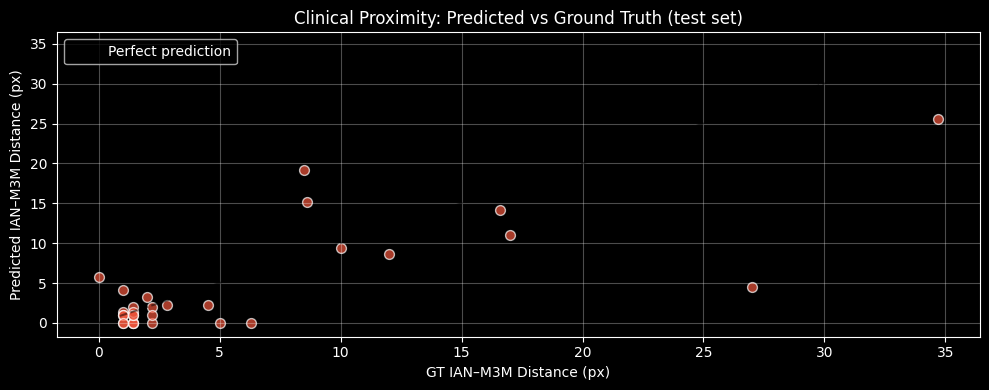


Pred vs GT proximity correlation: r = 0.7465


In [21]:
from scipy.spatial.distance import cdist

ian_model.eval(); m3m_model.eval()
proximity_records = []

with torch.no_grad():
    for i, info in enumerate(tqdm(test_ds.img_infos[:30], desc='Proximity analysis')):
        img_t, ian_gt, m3m_gt = test_ds[i]
        ian_prob = torch.sigmoid(ian_model(img_t.unsqueeze(0).to(DEVICE))).squeeze().cpu().numpy()
        m3m_prob = torch.sigmoid(m3m_model(img_t.unsqueeze(0).to(DEVICE))).squeeze().cpu().numpy()

        ian_bin = (ian_prob > 0.5).astype(np.uint8)
        m3m_bin = (m3m_prob > 0.5).astype(np.uint8)

        ian_pts = np.column_stack(np.where(ian_bin))
        m3m_pts = np.column_stack(np.where(m3m_bin))

        if len(ian_pts) > 5 and len(m3m_pts) > 5:
            # Sample for speed
            ian_s = ian_pts[np.random.choice(len(ian_pts), min(500, len(ian_pts)), replace=False)]
            m3m_s = m3m_pts[np.random.choice(len(m3m_pts), min(500, len(m3m_pts)), replace=False)]
            dist  = cdist(ian_s.astype(float), m3m_s.astype(float)).min()

            # GT proximity for reference
            ian_gt_pts = np.column_stack(np.where(ian_gt.squeeze().numpy() > 0))
            m3m_gt_pts = np.column_stack(np.where(m3m_gt.squeeze().numpy() > 0))
            if len(ian_gt_pts) > 0 and len(m3m_gt_pts) > 0:
                gt_s1 = ian_gt_pts[np.random.choice(len(ian_gt_pts), min(200, len(ian_gt_pts)), replace=False)]
                gt_s2 = m3m_gt_pts[np.random.choice(len(m3m_gt_pts), min(200, len(m3m_gt_pts)), replace=False)]
                gt_dist = cdist(gt_s1.astype(float), gt_s2.astype(float)).min()
            else:
                gt_dist = None

            proximity_records.append({
                'image':          info['file_name'],
                'pred_min_dist':  round(dist, 1),
                'gt_min_dist':    round(gt_dist, 1) if gt_dist is not None else None,
            })

if proximity_records:
    df_prox = pd.DataFrame(proximity_records).dropna()
    print(df_prox[['pred_min_dist', 'gt_min_dist']].describe().round(2))

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.scatter(df_prox['gt_min_dist'], df_prox['pred_min_dist'],
               alpha=0.7, color='#EF553B', edgecolors='white', s=50)
    lim = max(df_prox[['gt_min_dist','pred_min_dist']].max())
    ax.plot([0, lim], [0, lim], 'k--', alpha=0.5, label='Perfect prediction')
    ax.set_xlabel('GT IAN–M3M Distance (px)')
    ax.set_ylabel('Predicted IAN–M3M Distance (px)')
    ax.set_title('Clinical Proximity: Predicted vs Ground Truth (test set)')
    ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(MODEL_SAVE_DIR, 'proximity_scatter.png'), dpi=150, bbox_inches='tight')
    plt.show()

    corr = df_prox[['gt_min_dist','pred_min_dist']].corr().iloc[0,1]
    print(f'\nPred vs GT proximity correlation: r = {corr:.4f}')
    df_prox.to_csv(os.path.join(MODEL_SAVE_DIR, 'proximity_results.csv'), index=False)
else:
    print('No test images had both IAN and M3M detected at threshold=0.5')

## 20. Save All Outputs to Drive

In [22]:
# Copy mask_sanity.png if it was saved in working dir
mask_sanity_src = os.path.join(WORK_DIR, 'mask_sanity.png')
if os.path.exists(mask_sanity_src):
    shutil.copy(mask_sanity_src, os.path.join(MODEL_SAVE_DIR, 'mask_sanity.png'))

# Save full metrics JSON
import json as _json
all_metrics = {
    'IAN': {k: round(v, 4) for k, v in ian_test_metrics.items()},
    'M3M': {k: round(v, 4) for k, v in m3m_test_metrics.items()},
}
with open(os.path.join(MODEL_SAVE_DIR, 'test_metrics.json'), 'w') as f:
    _json.dump(all_metrics, f, indent=2)

print(f'All outputs in: {MODEL_SAVE_DIR}')
print('\nFiles saved:')
for root, dirs, files in os.walk(MODEL_SAVE_DIR):
    level = root.replace(MODEL_SAVE_DIR, '').count(os.sep)
    indent = '  ' * level
    if level < 2:
        for f in sorted(files):
            sz = os.path.getsize(os.path.join(root, f)) / 1e6
            print(f'  {indent}{f}  ({sz:.1f} MB)')

print('\n🏆 Model weights:')
print(f'  IAN: {ian_best_path}')
print(f'  M3M: {m3m_best_path}')

All outputs in: E:\IIT\NEW_FYP\MODELS\UNet_ResNet50

Files saved:
  ian_dice_distribution.png  (0.1 MB)
  mask_sanity.png  (0.4 MB)
  model_comparison.csv  (0.0 MB)
  model_comparison.png  (0.1 MB)
  proximity_results.csv  (0.0 MB)
  proximity_scatter.png  (0.1 MB)
  test_metrics.json  (0.0 MB)
  test_predictions.png  (2.1 MB)
  training_curves.png  (0.3 MB)
  unet_ian_best.pth  (196.6 MB)
  unet_m3m_best.pth  (196.3 MB)

🏆 Model weights:
  IAN: E:\IIT\NEW_FYP\MODELS\UNet_ResNet50\unet_ian_best.pth
  M3M: E:\IIT\NEW_FYP\MODELS\UNet_ResNet50\unet_m3m_best.pth
